#  EcoVision AI – Smart Waste Detection

## Project Overview
This Google Colab notebook trains and evaluates a YOLOv8 object-detection model for waste detection, analyzes predictions on test images, and provides a Gradio interface for image and video detection.

## Workflow
1. Install libraries and connect Google Drive.
2. Extract and prepare the dataset.
3. Load and train the YOLOv8 model.
4. Evaluate the trained model on the test split.
5. Visualize detections and count detected waste objects.
6. Launch the Gradio image/video detection interface.



In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


## 1. Install Dependencies and Connect Google Drive

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import zipfile

folder_path = "/content/drive/MyDrive/EcoVision_AI"

print(os.listdir(folder_path))

['Waste-Detection.v7i.yolov8.zip', 'runs']


## 2. Locate and Extract the Dataset

In [4]:
zip_path = "/content/drive/MyDrive/EcoVision_AI/Waste-Detection.v7i.yolov8.zip"

extract_path = "/content/EcoVision_AI"

In [5]:
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
print(os.listdir(extract_path))

['test', 'README.roboflow.txt', 'valid', 'train', 'data.yaml', 'README.dataset.txt']


In [7]:
yaml_path = "/content/EcoVision_AI/data.yaml"

with open(yaml_path, "r") as file:
    print(file.read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 6
names: ['Garbage_Bag', 'Glass', 'Paper_Bag', 'Pet_Bottle', 'Plastic_Bag', 'can']

roboflow:
  workspace: object-detection-cfmul
  project: waste-detection-0momv
  version: 7
  license: CC BY 4.0
  url: https://universe.roboflow.com/object-detection-cfmul/waste-detection-0momv/dataset/7


## 3. Configure the Dataset YAML File

In [8]:

import yaml

with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)

data["path"] = "/content/EcoVision_AI"
data["train"] = "train/images"
data["val"] = "valid/images"
data["test"] = "test/images"

with open(yaml_path, "w") as file:
    yaml.safe_dump(data, file, sort_keys=False)

print("YAML paths updated successfully!")

YAML paths updated successfully!


In [9]:
for folder in ["train", "valid", "test"]:

    image_path = os.path.join(
        extract_path, folder, "images"
    )

    label_path = os.path.join(
        extract_path, folder, "labels"
    )

    print("\n", folder.upper())

    print("Images:", len(os.listdir(image_path)))
    print("Labels:", len(os.listdir(label_path)))


 TRAIN
Images: 2012
Labels: 2012

 VALID
Images: 1411
Labels: 1411

 TEST
Images: 2480
Labels: 2480


## 4. Check Training, Validation, and Test Data


## Step 1. Load the pretrained model

## 5. Load the Pretrained YOLOv8 Model

In [10]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLOv8 model loaded successfully!


## Step 2. Train the model

## 6. Train the YOLOv8 Waste Detection Model

In [12]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data="/content/EcoVision_AI/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/drive/MyDrive/EcoVision_AI/runs",
    name="waste_detection",
    exist_ok=True)

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/EcoVision_AI/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=waste_detection, nbs=64, nms=None, opset=None, optimize=F

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x791d1cf4fa10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
     

In [13]:
import os

model_path = "/content/drive/MyDrive/EcoVision_AI/runs/waste_detection/weights"

print(os.listdir(model_path))

['last.pt', 'best.pt']


## 7. Locate the Trained Model Weights

In [14]:
# Load the best trained model
best_model = YOLO(
    "/content/drive/MyDrive/EcoVision_AI/runs/waste_detection/weights/best.pt"
)

# Evaluate using test dataset
test_metrics = best_model.val(
    data="/content/EcoVision_AI/data.yaml",
    split="test",
    device=0
)

# Display results
print("Test Precision:", test_metrics.box.mp)
print("Test Recall:", test_metrics.box.mr)
print("Test mAP50:", test_metrics.box.map50)
print("Test mAP50-95:", test_metrics.box.map)

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1543.2±762.9 MB/s, size: 52.0 KB)
val: Scanning /content/EcoVision_AI/test/labels... 2480 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2480/2480 2.1Kit/s 1.2s
val: New cache created: /content/EcoVision_AI/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 2951. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 155/155 6.2it/s 24.9s
                   all       2480       2951      0.709      0.627      0.676      0.454
           Garbage_Bag        246        421       0.62       0.57

## 8. Evaluate the Model on the Test Dataset

In [17]:
import glob

test_images = glob.glob(
    "/content/EcoVision_AI/test/images/*"
)

print("Total test images:", len(test_images))

Total test images: 2480


## 9. Load Test Images

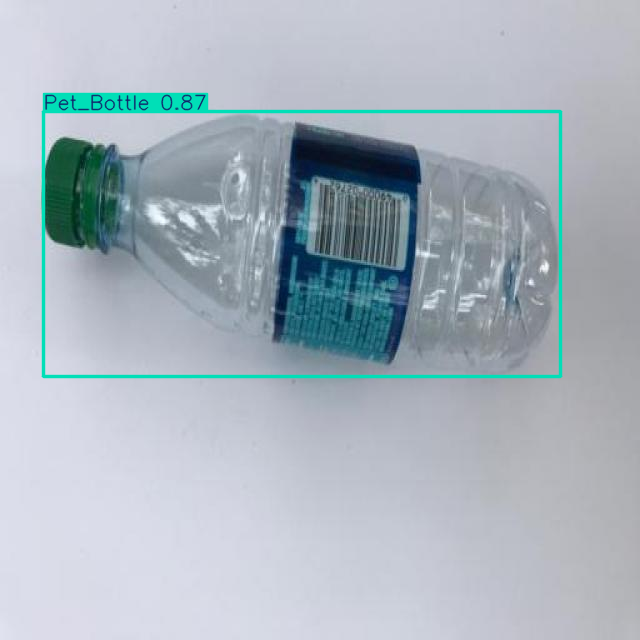

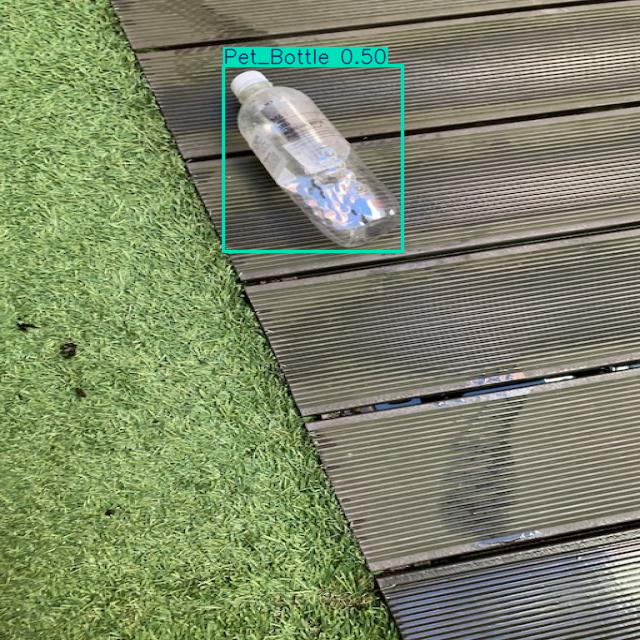

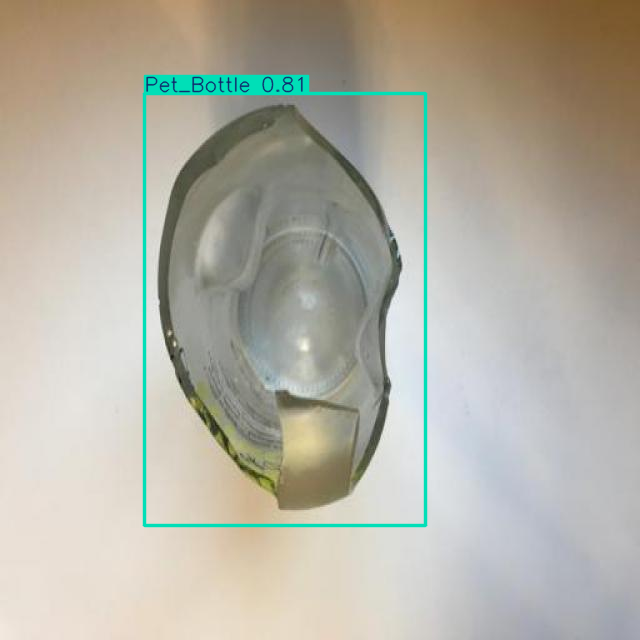

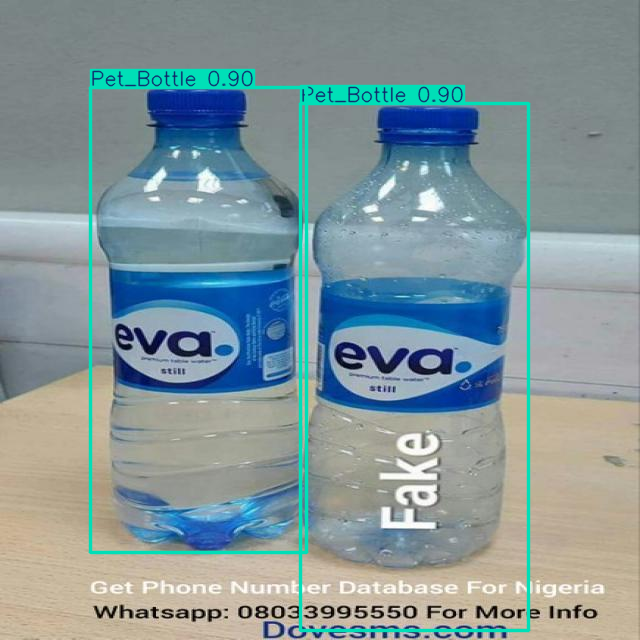

In [18]:
# Display test images with predictions

from PIL import Image

for image_path in test_images[6:10]:

    results = best_model.predict(
        source=image_path,
        conf=0.25,
        verbose=False
    )

    predicted_image = results[0].plot()

    display(Image.fromarray(predicted_image[:, :, ::-1]))


## 10. Visualize Detection Results

In [19]:
from collections import Counter

class_counts = Counter()

for image_path in test_images[:100]:

    results = best_model.predict(
        source=image_path,
        conf=0.25,
        verbose=False
    )

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        class_name = best_model.names[class_id]

        class_counts[class_name] += 1

print("Detected waste objects:")

for class_name, count in class_counts.items():
    print(class_name, ":", count)

Detected waste objects:
Paper_Bag : 18
Glass : 17
Pet_Bottle : 21
can : 19
Plastic_Bag : 4
Garbage_Bag : 19


## 11. Count Detected Waste Objects

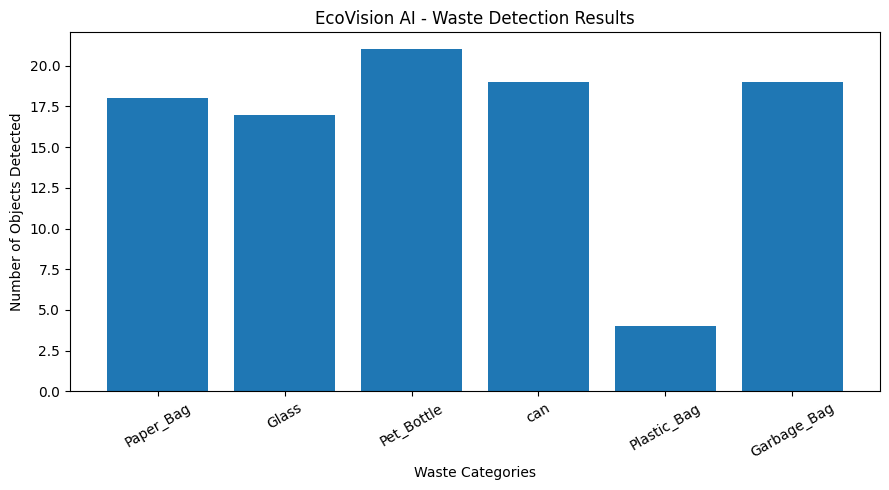

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("EcoVision AI - Waste Detection Results")
plt.xlabel("Waste Categories")
plt.ylabel("Number of Objects Detected")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 12. Plot Waste Detection Counts

In [21]:
!pip install -q gradio ultralytics

## 13. Install Gradio and Load the Trained Model

In [22]:
best_model = YOLO(
    "/content/drive/MyDrive/EcoVision_AI/runs/waste_detection/weights/best.pt"
)

print("EcoVision AI model loaded successfully!")
print(best_model.names)

EcoVision AI model loaded successfully!
{0: 'Garbage_Bag', 1: 'Glass', 2: 'Paper_Bag', 3: 'Pet_Bottle', 4: 'Plastic_Bag', 5: 'can'}


##  Create the waste detection function

## 14. Create Image and Video Detection Functions

In [23]:

import gradio as gr
import cv2
import tempfile

# Image Detection
def detect_waste(image):

    if image is None:
        return None, "Upload an image."

    result = best_model.predict(image, conf=0.25)[0]

    output = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

    detections = []

    for box in result.boxes:
        name = best_model.names[int(box.cls[0])]
        confidence = float(box.conf[0]) * 100
        detections.append(f"{name}: {confidence:.2f}%")

    message = "\n".join(detections) if detections else "No waste detected."

    return output, message


# Video Detection
def detect_waste_video(video):

    if video is None:
        return None, "Upload a video."

    cap = cv2.VideoCapture(video)

    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    width = int(cap.get(3))
    height = int(cap.get(4))

    output = tempfile.NamedTemporaryFile(suffix=".mp4", delete=False).name

    writer = cv2.VideoWriter(
        output, cv2.VideoWriter_fourcc(*"mp4v"),
        fps, (width, height)
    )

    counts = {}
    frames = 0

    while True:
        success, frame = cap.read()

        if not success:
            break

        result = best_model.predict(frame, conf=0.25)[0]
        writer.write(result.plot())

        for box in result.boxes:
            name = best_model.names[int(box.cls[0])]
            counts[name] = counts.get(name, 0) + 1

        frames += 1

    cap.release()
    writer.release()

    message = f"Frames: {frames}\n"

    for name, count in counts.items():
        message += f"{name}: {count}\n"

    if not counts:
        message += "No waste detected."

    return output, message


print("Image and Video Detection Ready!")


Image and Video Detection Ready!


# Gradio Interface

## 15. Build and Launch the Gradio Interface

In [27]:
import gradio as gr
import os
from PIL import Image

def detect_file(file):
    if file is None:
        return (
            gr.update(visible=False),
            gr.update(visible=False),
            "Please upload a file."
        )

    ext = os.path.splitext(file)[1].lower()

    if ext in [".jpg", ".jpeg", ".png", ".webp"]:
        result, message = detect_waste(Image.open(file))
        return (
            gr.update(value=result, visible=True),
            gr.update(visible=False),
            message
        )

    elif ext in [".mp4", ".avi", ".mov", ".mkv"]:
        result, message = detect_waste_video(file)
        return (
            gr.update(visible=False),
            gr.update(value=result, visible=True),
            message
        )

    return (
        gr.update(visible=False),
        gr.update(visible=False),
        "Unsupported file format."
    )


with gr.Blocks(theme=gr.themes.Soft()) as app:
    gr.Markdown("# 🌱 EcoVision AI - Smart Waste Detection")
    gr.Markdown("Upload an image or video to detect waste objects.")

    with gr.Row():
        with gr.Column():
            file = gr.File(
                label="Upload Image or Video",
                file_types=["image", "video"],
                type="filepath"
            )
            button = gr.Button("Detect Waste", variant="primary")

        with gr.Column():
            image_output = gr.Image(label="Image Detection Output", visible=False)
            video_output = gr.Video(label="Video Detection Output", visible=False)
            results = gr.Textbox(
                label="Waste Detection Results",
                lines=5
            )

    button.click(
        fn=detect_file,
        inputs=file,
        outputs=[image_output, video_output, results]
    )

app.launch(share=True)


/tmp/ipykernel_486/1992998160.py:23: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d100f0394ff1197180.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [39]:
import shutil

shutil.make_archive(
    '/content/EcoVision_AI_Complete',
    'zip',
    '/content/drive/MyDrive/EcoVision_AI'
)

'/content/EcoVision_AI_Complete.zip'

## 16. Download the Project Folder as a ZIP

In [41]:
from google.colab import files

files.download('/content/EcoVision_AI_Complete.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>